In [1]:
import sys
from pathlib import Path

project_root = Path("/mnt/x/segmentation_cfos")
sys.path.insert(0, str(project_root))

import numpy as np
import matplotlib.pyplot as plt
import random
from src.data.io_utils import read_tif_image, convert_image_to_array

In [2]:
N_SAMPLES = 5000 
SEED = 42  

masks_patches = Path("/mnt/x/donnees/pachs_64_3classes/masks")
mask_files = sorted(masks_patches.glob("*.tif"))

print(f"Total patches disponibles: {len(mask_files)}")
print(f"Patches à analyser: {N_SAMPLES}")
print(f"Seed: {SEED}")

Total patches disponibles: 19657
Patches à analyser: 5000
Seed: 42


In [3]:
random.seed(SEED)
selected_files = random.sample(mask_files, min(N_SAMPLES, len(mask_files)))

print(f"✅ {len(selected_files)} patches sélectionnés aléatoirement")

# Analyse des classes
print("Analyse en cours...")

total_voxels = 0
total_class0 = 0
total_class1 = 0
total_class2 = 0

for i, mask_file in enumerate(selected_files):
    mask_sitk = read_tif_image(str(mask_file))
    mask = convert_image_to_array(mask_sitk)
    
    total_voxels += mask.size
    total_class0 += (mask == 0).sum()
    total_class1 += (mask == 1).sum()
    total_class2 += (mask == 2).sum()
    
    if (i + 1) % 1000 == 0:
        print(f"  Traité {i+1}/{len(selected_files)} patches")

print(f"✅ Analyse terminée sur {len(selected_files)} patches")

✅ 5000 patches sélectionnés aléatoirement
Analyse en cours...
  Traité 1000/5000 patches
  Traité 2000/5000 patches
  Traité 3000/5000 patches
  Traité 4000/5000 patches
  Traité 5000/5000 patches
✅ Analyse terminée sur 5000 patches


In [4]:
pct0 = (total_class0 / total_voxels) * 100
pct1 = (total_class1 / total_voxels) * 100
pct2 = (total_class2 / total_voxels) * 100

print("=" * 50)
print("RÉSULTATS - DISTRIBUTION DES CLASSES")
print("=" * 50)
print(f"Total patches analysés: {len(selected_files):,}")
print(f"Total voxels analysés: {total_voxels:,}")
print()
print(f"Classe 0 (Fond):        {pct0:.2f}%  ({total_class0:,} voxels)")
print(f"Classe 1 (Neurones):    {pct1:.4f}%  ({total_class1:,} voxels)")
print(f"Classe 2 (Vaisseaux):   {pct2:.4f}%  ({total_class2:,} voxels)")
print()
print(f"Ratio Fond/Neurones:     {total_class0/total_class1:.1f}")
print(f"Ratio Fond/Vaisseaux:    {total_class0/total_class2:.1f}")


RÉSULTATS - DISTRIBUTION DES CLASSES
Total patches analysés: 5,000
Total voxels analysés: 1,310,720,000

Classe 0 (Fond):        99.30%  (1,301,479,620 voxels)
Classe 1 (Neurones):    0.1074%  (1,407,413 voxels)
Classe 2 (Vaisseaux):   0.5976%  (7,832,967 voxels)

Ratio Fond/Neurones:     924.7
Ratio Fond/Vaisseaux:    166.2


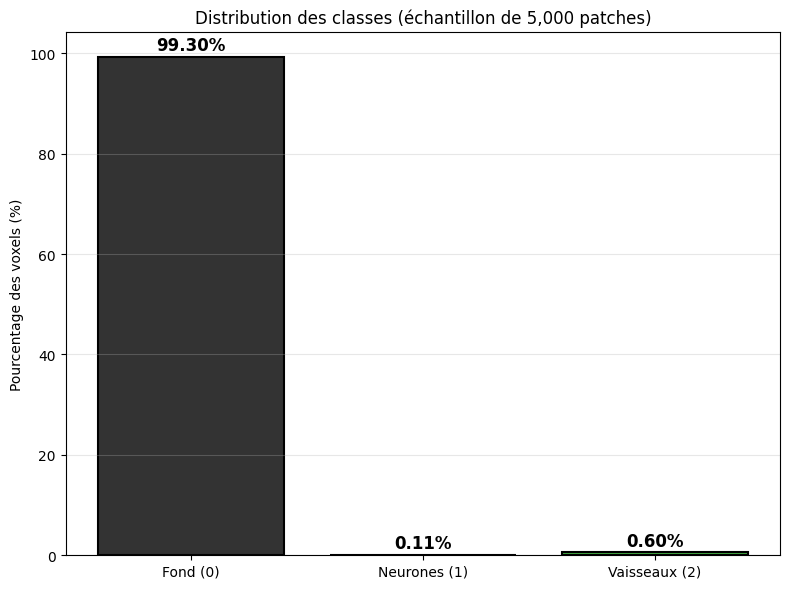

In [5]:
fig, ax = plt.subplots(figsize=(8, 6))

classes = ['Fond (0)', 'Neurones (1)', 'Vaisseaux (2)']
percentages = [pct0, pct1, pct2]
colors = ['#333333', '#FF4444', '#44AA44']

bars = ax.bar(classes, percentages, color=colors, edgecolor='black', linewidth=1.5)

# Ajouter les valeurs sur les barres
for bar, pct in zip(bars, percentages):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{pct:.2f}%', ha='center', va='bottom', fontsize=12, fontweight='bold')

ax.set_ylabel('Pourcentage des voxels (%)')
ax.set_title(f'Distribution des classes (échantillon de {len(selected_files):,} patches)')
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()


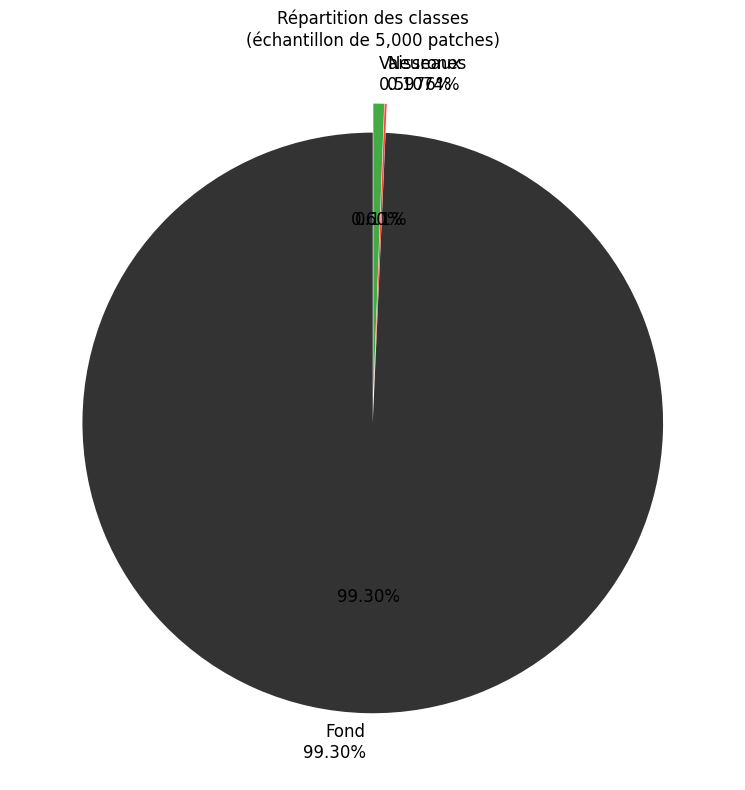

In [6]:
fig, ax = plt.subplots(figsize=(8, 8))

labels = [f'Fond\n{pct0:.2f}%', f'Neurones\n{pct1:.4f}%', f'Vaisseaux\n{pct2:.4f}%']
colors = ['#333333', '#FF4444', '#44AA44']
explode = (0.02, 0.08, 0.08)

wedges, texts, autotexts = ax.pie(
    percentages, 
    labels=labels, 
    colors=colors, 
    explode=explode,
    autopct='%1.2f%%',
    startangle=90,
    textprops={'fontsize': 12}
)

ax.set_title(f'Répartition des classes\n(échantillon de {len(selected_files):,} patches)')

plt.tight_layout()
plt.show()

In [7]:
print("\n" + "=" * 50)
print("STATISTIQUES DÉTAILLÉES")
print("=" * 50)

print(f"""
┌─────────────────────────────────────────────────────────────┐
│                    RÉPARTITION DES CLASSES                   │
├─────────────────────────────┬───────────────────────────────┤
│ Classe 0 (Fond)             │ {pct0:>6.2f}%  ({total_class0:>12,} voxels) │
│ Classe 1 (Neurones)         │ {pct1:>6.4f}%  ({total_class1:>12,} voxels) │
│ Classe 2 (Vaisseaux)        │ {pct2:>6.4f}%  ({total_class2:>12,} voxels) │
├─────────────────────────────┴───────────────────────────────┤
│ Total voxels: {total_voxels:,}                                       │
│ Patches analysés: {len(selected_files):,}                                │
└─────────────────────────────────────────────────────────────┘
""")

print(f"Ratio Fond / Neurones:     {total_class0/total_class1:.1f}")
print(f"Ratio Fond / Vaisseaux:    {total_class0/total_class2:.1f}")
print(f"Ratio Neurones / Vaisseaux: {total_class1/total_class2:.1f}")


STATISTIQUES DÉTAILLÉES

┌─────────────────────────────────────────────────────────────┐
│                    RÉPARTITION DES CLASSES                   │
├─────────────────────────────┬───────────────────────────────┤
│ Classe 0 (Fond)             │  99.30%  (1,301,479,620 voxels) │
│ Classe 1 (Neurones)         │ 0.1074%  (   1,407,413 voxels) │
│ Classe 2 (Vaisseaux)        │ 0.5976%  (   7,832,967 voxels) │
├─────────────────────────────┴───────────────────────────────┤
│ Total voxels: 1,310,720,000                                       │
│ Patches analysés: 5,000                                │
└─────────────────────────────────────────────────────────────┘

Ratio Fond / Neurones:     924.7
Ratio Fond / Vaisseaux:    166.2
Ratio Neurones / Vaisseaux: 0.2


In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(['Distribution'], [100], color='#333333', edgecolor='black', 
       label=f'Fond: {pct0:.2f}%')
ax.bar(['Distribution'], [pct1 + pct2], bottom=[pct0], color='#44AA44', 
       edgecolor='black', label=f'Vaisseaux: {pct2:.4f}%')
ax.bar(['Distribution'], [pct1], bottom=[pct0], color='#FF4444', 
       edgecolor='black', label=f'Neurones: {pct1:.4f}%')

ax.set_ylabel('Pourcentage des voxels (%)')
ax.set_title('Distribution des classes (barres empilées)')
ax.legend(loc='upper right')
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()


In [ ]:
print("\n" + "=" * 50)
print("VÉRIFICATION DE L'ÉCHANTILLON")
print("=" * 50)
has_neurons = []
has_vessels = []

for mask_file in selected_files[:100]:  # Vérifier sur 100 patches
    mask_sitk = read_tif_image(str(mask_file))
    mask = convert_image_to_array(mask_sitk)
    has_neurons.append((mask == 1).sum() > 0)
    has_vessels.append((mask == 2).sum() > 0)

print(f"Sur 100 patches vérifiés:")
print(f"  Patches avec neurones: {sum(has_neurons)}")
print(f"  Patches avec vaisseaux: {sum(has_vessels)}")
print(f"  Patches avec les deux: {sum(1 for n, v in zip(has_neurons, has_vessels) if n and v)}")
print(f"  Patches fond pur: {sum(1 for n, v in zip(has_neurons, has_vessels) if not n and not v)}")

if sum(has_neurons) > 0 and sum(has_vessels) > 0:
    print("\n✅ Échantillon représentatif: contient neurones ET vaisseaux")
else:
    print("\n⚠️ Échantillon non représentatif")

In [ ]:
output_dir = project_root / "outputs" / "statistics"
output_dir.mkdir(parents=True, exist_ok=True)

import json

results = {
    "total_patches_analyzed": len(selected_files),
    "total_voxels": int(total_voxels),
    "class_0_voxels": int(total_class0),
    "class_1_voxels": int(total_class1),
    "class_2_voxels": int(total_class2),
    "class_0_percentage": float(pct0),
    "class_1_percentage": float(pct1),
    "class_2_percentage": float(pct2),
    "ratio_background_neurons": float(total_class0 / total_class1),
    "ratio_background_vessels": float(total_class0 / total_class2)
}

with open(output_dir / "class_distribution_3classes.json", "w") as f:
    json.dump(results, f, indent=2)

print(f"\n✅ Résultats sauvegardés: {output_dir / 'class_distribution_3classes.json'}")

print("\n" + "=" * 50)
print("✅ NOTEBOOK TERMINÉ")
print("=" * 50)